# Pricing Model for Sublimation Print Orders
**Author:** Yana Atanasova

**Course:** Final Exam Project

## 1. Title & Introduction
When I price a custom sublimation print order (mugs, t-shirts, mousepads,
invitations), I need to know how much it actually costs me: blanks, ink,
paper, press time, design time and wasted items. Pricing by gut feeling often
leads to losing money on small orders or being too expensive on large ones.

In this project I build a **linear regression model** that predicts the
cost of an order from its characteristics, and then use it to recommend a
selling price with a profit margin.

The reader will see how a statistical model is built step by step: cleaning
the data, exploring it, deriving the mathematics of least squares, fitting
the model with matrices and with libraries, checking its quality, and
turning the result into a practical price calculator.

*Note: the dataset used here is simulated, because I did not have enough
structured records of real orders. The method can be applied to real data
without changes.*

In [ ]:
# %pip install pandas numpy matplotlib statsmodels scikit-learn

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

## 2. Problem Formulation

### Real-world problem

When pricing a custom sublimation print order, it is necessary to estimate the
true production cost before setting the selling price.

The production cost may depend on the product type, quantity, printed area,
ink consumption, paper consumption, heat-press time, design time and production
waste.

The goal of this project is to build a statistical model that estimates the
production cost of a new order and then uses this estimate to calculate a
recommended selling price.

### Mathematical formulation

Let \(y\) denote the total production cost of an order, measured in EUR.

Let the explanatory variables be:

- \(x_1\) = quantity
- \(x_2\) = printed area
- \(x_3\) = ink used in millilitres
- \(x_4\) = number of paper sheets
- \(x_5\) = heat-press time in minutes
- \(x_6\) = design time in minutes
- \(x_7\) = percentage of wasted production

The multiple linear regression model can be written as:

$$
y =
\beta_0 +
\beta_1x_1 +
\beta_2x_2 +
\beta_3x_3 +
\beta_4x_4 +
\beta_5x_5 +
\beta_6x_6 +
\beta_7x_7 +
\varepsilon
$$

where:

- \(\beta_0\) is the intercept;
- \(\beta_j\) represents the expected change in production cost when
  \(x_j\) increases by one unit, while the other variables remain constant;
- \(\varepsilon\) represents the random error that is not explained by the model.

For a new order, the estimated production cost is:

$$
\hat{y} =
\hat{\beta}_0 +
\hat{\beta}_1x_1 +
\hat{\beta}_2x_2 +
\dots +
\hat{\beta}_7x_7
$$

### Selling price

The estimated production cost alone is not the final selling price.

Let \(m\) denote the desired profit margin, where:

$$
0 < m < 1
$$

If \(P\) is the selling price, the profit is:

$$
\text{Profit} = P-\hat{y}
$$

The profit margin is defined as:

$$
m = \frac{P-\hat{y}}{P}
$$

Solving the equation for \(P\):

$$
P-\hat{y}=mP
$$

$$
P(1-m)=\hat{y}
$$

Therefore, the recommended selling price is:

$$
\boxed{
P=\frac{\hat{y}}{1-m}
}
$$

For example, if the predicted production cost is \(20\) EUR and the desired
profit margin is \(30\%\), then:

$$
P=\frac{20}{1-0.30}
=\frac{20}{0.70}
\approx 28.57\text{ EUR}
$$

The resulting profit is:

$$
28.57-20=8.57\text{ EUR}
$$

and the profit margin is:

$$
\frac{8.57}{28.57}\approx0.30=30\%
$$

### Assumptions

The regression model is based on the following assumptions:

1. The relationship between the production cost and the explanatory variables
   is approximately linear.
2. The observations are independent.
3. The expected value of the error is zero:

$$
E(\varepsilon)=0
$$

4. The variance of the errors is approximately constant:

$$
Var(\varepsilon)=\sigma^2
$$

5. The residuals are approximately normally distributed when statistical
   inference is required.
6. The observed orders are representative of the type of orders for which the
   model will be used.

### Limitations

The dataset is simulated rather than collected from a large number of real
business orders. Therefore, the results describe the simulated environment
and should not be interpreted as a universal pricing formula.

The model may also fail to capture factors such as quantity discounts,
supplier price changes, electricity costs, packaging costs, marketplace fees
and seasonal demand.

## 3. Mathematical Background
**Matrix form.** Suppose we have $N$ orders. We collect the predictors in a
matrix $X$ of size $N \times (p+1)$, where each row is one order and the
first column is all ones (it corresponds to $\beta_0$). The costs form a
vector $y$ and the coefficients a vector $\beta$. The model becomes

$$y = X\beta + \varepsilon.$$

**Ordinary Least Squares (OLS).** We choose $\beta$ so that the predictions
$X\beta$ are as close as possible to $y$, by minimizing the sum of squared
errors:

$$S(\beta) = \|y - X\beta\|^2 = (y - X\beta)^T (y - X\beta).$$

To find the minimum, we take the derivative with respect to $\beta$ and set
it to zero:

$$\frac{\partial S}{\partial \beta} = -2X^T y + 2X^T X \beta = 0
\quad\Longrightarrow\quad X^T X \beta = X^T y.$$

If the columns of $X$ are linearly independent, $X^T X$ is invertible and

$$\hat\beta = (X^T X)^{-1} X^T y.$$

**Residuals.** The fitted values are $\hat y = X\hat\beta$ and the residuals
are $e_i = y_i - \hat y_i$. A good model has small residuals without any
visible pattern.

**Coefficient of determination.** $R^2$ measures what fraction of the
variation in the costs the model explains:

$$R^2 = 1 - \frac{\sum_i (y_i - \hat y_i)^2}{\sum_i (y_i - \bar y)^2}.$$

It is between 0 and 1, and values close to 1 mean a good fit.

**Model assumptions.** OLS gives reliable results when the assumptions from
Section 2 hold: linearity, independent errors with mean zero and constant
variance, and approximately normal errors. We check them in Section 7 using
residual plots.

**Ridge regression.** When predictors are strongly correlated (for example,
ink used and quantity), the coefficients of OLS can become unstable. Ridge
regression adds a penalty for large coefficients:

$$\hat\beta_{ridge} = \arg\min_\beta \; \|y - X\beta\|^2 + \lambda \sum_{j=1}^{p} \beta_j^2
\quad\Longrightarrow\quad \hat\beta_{ridge} = (X^T X + \lambda I)^{-1} X^T y,$$

where $\lambda \ge 0$ controls the strength of the penalty.
For $\lambda = 0$ we get OLS back. For simplicity the closed form above assumes that the data are centered, so the intercept is not penalized. We compare both methods in Section 8.

## 4. Data

**Source.** The dataset is **simulated**. I did not have enough structured
records of real orders, so I generated 60 orders with the script
`generate_data.py`. Each order's cost is computed from a known formula
(prices of blanks, ink, paper and labor) plus a small random noise. This
means the model can be tested in a controlled setting, but the results
describe the simulation and not a real workshop.

**Columns.**

| Column | Description |
|---|---|
| `order_id` | Unique number of the order |
| `product_type` | Product: mug, t-shirt, mousepad, phone case or invitation |
| `quantity` | Number of items in the order |
| `area_cm2` | Printed area of one item (cm²) |
| `ink_ml` | Ink used for the whole order (ml) |
| `paper_sheets` | Sublimation paper sheets used |
| `press_time_min` | Time in the heat press (minutes) |
| `design_time_min` | Time spent on the design (minutes) |
| `waste_pct` | Percentage of items wasted (misprints) |
| `total_cost_eur` | **Target variable:** total cost of the order (EUR) |

**Data problems on purpose.** To practice data cleaning, a few missing
values and one outlier were added to the simulated data. The cleaning steps
are shown below.

In [5]:
df = pd.read_csv("orders.csv")
df.head()

,order_id,product_type,quantity,area_cm2,ink_ml,paper_sheets,press_time_min,design_time_min,waste_pct,total_cost_eur
0,1,mug,19,179.2,9.15,6,36.2,88.0,5.3,68.36
1,2,mousepad,3,411.6,3.36,3,12.4,76.0,6.2,19.23
2,3,mug,14,180.8,6.88,5,41.9,38.0,8.1,49.54
3,4,phone_case,10,57.9,1.52,1,22.3,65.0,10.4,45.08
4,5,mousepad,7,413.4,7.68,6,16.9,48.0,2.9,25.74


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   order_id         60 non-null     int64  
 1   product_type     60 non-null     str    
 2   quantity         60 non-null     int64  
 3   area_cm2         60 non-null     float64
 4   ink_ml           58 non-null     float64
 5   paper_sheets     60 non-null     int64  
 6   press_time_min   60 non-null     float64
 7   design_time_min  58 non-null     float64
 8   waste_pct        58 non-null     float64
 9   total_cost_eur   60 non-null     float64
dtypes: float64(6), int64(3), str(1)
memory usage: 4.8 KB


In [7]:
df.isna().sum()

order_id           0
product_type       0
quantity           0
area_cm2           0
ink_ml             2
paper_sheets       0
press_time_min     0
design_time_min    2
waste_pct          2
total_cost_eur     0
dtype: int64

In [8]:
for col in ["ink_ml", "waste_pct", "design_time_min"]:
    df[col] = df[col].fillna(
        df.groupby("product_type")[col].transform("median")
    )

df.isna().sum()

order_id           0
product_type       0
quantity           0
area_cm2           0
ink_ml             0
paper_sheets       0
press_time_min     0
design_time_min    0
waste_pct          0
total_cost_eur     0
dtype: int64

In [10]:
df_clean = df.copy()

In [11]:
df_clean.isna().sum()

order_id           0
product_type       0
quantity           0
area_cm2           0
ink_ml             0
paper_sheets       0
press_time_min     0
design_time_min    0
waste_pct          0
total_cost_eur     0
dtype: int64

In [12]:
df_clean.describe()

,order_id,quantity,area_cm2,ink_ml,paper_sheets,press_time_min,design_time_min,waste_pct,total_cost_eur
count,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000,60.00000,60.000000,60.000000
mean,30.500000,18.316667,279.501667,14.549333,9.733333,45.443333,54.60000,5.081667,40.162000
std,17.464249,23.141050,176.825636,22.406267,13.017416,51.618875,23.15548,2.606478,21.734793
min,1.000000,1.000000,52.500000,0.310000,1.000000,7.500000,12.00000,0.000000,10.480000
25%,15.750000,4.750000,67.250000,1.660000,1.000000,15.725000,37.25000,3.675000,23.227500
50%,30.500000,10.000000,294.750000,7.040000,5.000000,28.700000,56.00000,5.050000,36.580000
75%,45.250000,18.250000,415.100000,17.710000,13.000000,49.275000,73.25000,6.700000,54.660000
max,60.000000,117.000000,645.000000,134.040000,66.000000,284.800000,90.00000,10.400000,104.910000


In [13]:
df["cost_per_unit"] = df["total_cost_eur"] / df["quantity"]
median = df.groupby("product_type")["cost_per_unit"].transform("median")
df["ratio"] = df["cost_per_unit"] / median
df.sort_values("ratio", ascending=False).head(5)

,order_id,product_type,quantity,area_cm2,ink_ml,paper_sheets,press_time_min,design_time_min,waste_pct,total_cost_eur,cost_per_unit,ratio
30,31,phone_case,8,56.8,1.04,1,27.4,46.0,10.3,104.91,13.113750,2.766760
52,53,t-shirt,1,645.0,1.57,2,7.5,77.0,4.8,19.00,19.000000,1.980714
50,51,phone_case,2,61.4,0.32,1,8.4,72.0,7.1,18.04,9.020000,1.903054
47,48,mousepad,3,554.7,4.07,3,12.1,65.0,5.3,19.24,6.413333,1.857879
1,2,mousepad,3,411.6,3.36,3,12.4,76.0,6.2,19.23,6.410000,1.856914


In [15]:
df_clean = df[df["ratio"] < 2].drop(columns=["cost_per_unit", "ratio"])
print(df_clean.shape)
df_clean.to_csv("orders_clean.csv", index=False)

(59, 10)


Missing values in ink_ml, waste_pct and design_time_min were filled with the median of the 
same product type. One order with an unusually high cost per unit was removed as an outlier.

## 5. Exploratory Analysis

Before building a model, we look at the data. For each numeric variable we compute the mean $\bar x = \frac{1}{N}\sum_i x_i$, the standard deviation $s = \sqrt{\frac{1}{N-1}\sum_i (x_i-\bar x)^2}$ and the quartiles (the values below which 25%, 50% and 75% of the observations lie).

In [16]:
df_clean.describe().round(2)

,order_id,quantity,area_cm2,ink_ml,paper_sheets,press_time_min,design_time_min,waste_pct,total_cost_eur
count,59.00,59.00,59.00,59.00,59.00,59.00,59.00,59.00,59.00
mean,30.49,18.49,283.28,14.78,9.88,45.75,54.75,4.99,39.06
std,17.61,23.30,175.89,22.53,13.08,52.01,23.33,2.54,20.18
min,1.00,1.00,52.50,0.31,1.00,7.50,12.00,0.00,10.48
25%,15.50,4.50,122.25,1.76,1.50,15.65,36.50,3.55,23.04
50%,30.00,10.00,302.00,7.20,5.00,29.10,56.00,5.00,36.37
75%,45.50,18.50,416.80,17.85,13.00,49.65,73.50,6.55,52.93
max,60.00,117.00,645.00,134.04,66.00,284.80,90.00,10.40,99.14


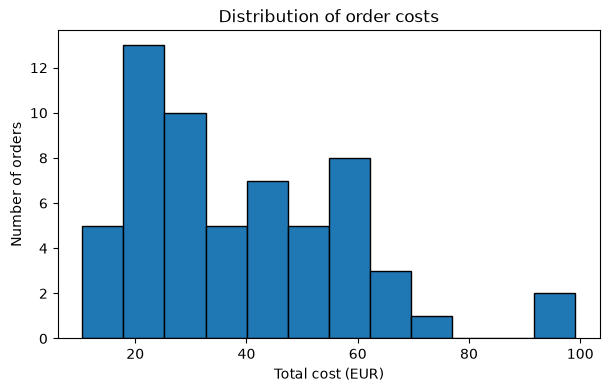

In [18]:
plt.figure(figsize=(7, 4))
plt.hist(df_clean["total_cost_eur"], bins=12, edgecolor="black")
plt.xlabel("Total cost (EUR)")
plt.ylabel("Number of orders")
plt.title("Distribution of order costs")
plt.show()

The histogram shows that the cost of an order varies a lot. Most orders are small: more than half cost less than 40 EUR, and the largest group is between 20 and 30 EUR. There is a second, smaller group of orders around 50-70 EUR, and only a few orders cost more than 70 EUR. The average cost is about 39 EUR, but the median is lower (about 36 EUR), because a few expensive orders pull the average up. This wide spread is a reason why a single flat price for every order would not work, and why it is useful to model the cost from the order's characteristics.

### Correlations

To see which variables are related, we use the Pearson correlation coefficient between two variables $x$ and $y$:

$$r = \frac{\sum_i (x_i-\bar x)(y_i-\bar y)}{\sqrt{\sum_i (x_i-\bar x)^2 \,\sum_i (y_i-\bar y)^2}}.$$

It is always between $-1$ and $1$. Values close to $1$ mean that the variables grow together, values close to $-1$ 
mean that one grows when the other falls, and values close to $0$ mean no linear relationship.

In [19]:
cols = ["quantity", "area_cm2", "ink_ml", "paper_sheets",
        "press_time_min", "design_time_min", "waste_pct", "total_cost_eur"]
corr = df_clean[cols].corr().round(2)
corr

,quantity,area_cm2,ink_ml,paper_sheets,press_time_min,design_time_min,waste_pct,total_cost_eur
quantity,1.00,0.11,0.95,0.97,0.99,-0.06,-0.04,0.59
area_cm2,0.11,1.00,0.24,0.27,0.10,0.16,-0.14,0.12
ink_ml,0.95,0.24,1.00,0.98,0.95,-0.04,-0.06,0.57
paper_sheets,0.97,0.27,0.98,1.00,0.95,-0.02,-0.06,0.59
press_time_min,0.99,0.10,0.95,0.95,1.00,-0.03,-0.06,0.61
design_time_min,-0.06,0.16,-0.04,-0.02,-0.03,1.00,-0.10,0.32
waste_pct,-0.04,-0.14,-0.06,-0.06,-0.06,-0.10,1.00,-0.16
total_cost_eur,0.59,0.12,0.57,0.59,0.61,0.32,-0.16,1.00


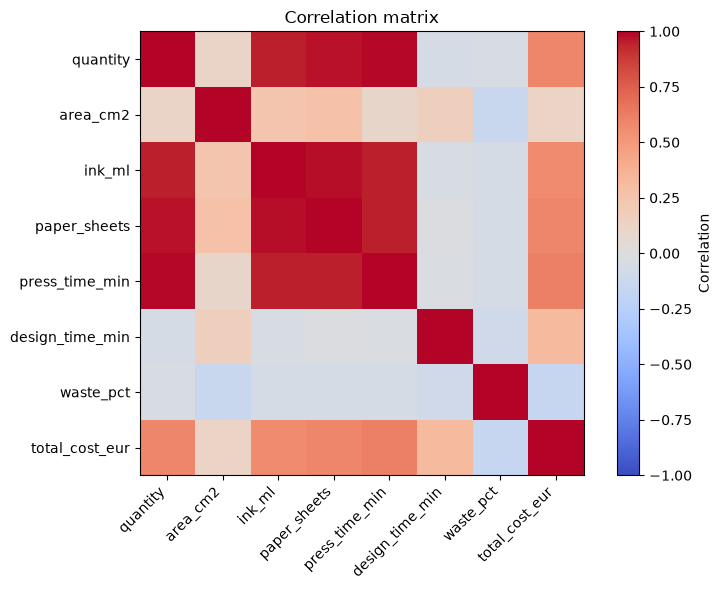

In [20]:
plt.figure(figsize=(8, 6))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(cols)), cols, rotation=45, ha="right")
plt.yticks(range(len(cols)), cols)
plt.title("Correlation matrix")
plt.tight_layout()
plt.show()

### Multicollinearity

The correlation matrix shows strong relationships between some explanatory
variables. For example, quantity is strongly correlated with ink consumption,
paper consumption and heat-press time.

This situation is known as **multicollinearity**.

Multicollinearity occurs when two or more explanatory variables contain similar
information. In a regression model, this can make the estimated coefficients
unstable.

The correlation coefficient between two variables \(X\) and \(Y\) is:

$$
r_{XY}
=
\frac{
\sum_{i=1}^{n}(x_i-\bar{x})(y_i-\bar{y})
}{
\sqrt{
\sum_{i=1}^{n}(x_i-\bar{x})^2
\sum_{i=1}^{n}(y_i-\bar{y})^2
}
}
$$

The value of \(r\) is between \(-1\) and \(1\):

$$
-1 \leq r \leq 1
$$

Values close to \(1\) indicate a strong positive linear relationship, while
values close to \(-1\) indicate a strong negative relationship.

In this project, strong correlations between production variables are
expected because larger orders generally require more materials and more
production time.

Because of this multicollinearity, Ridge regression will later be compared
with Ordinary Least Squares (OLS).

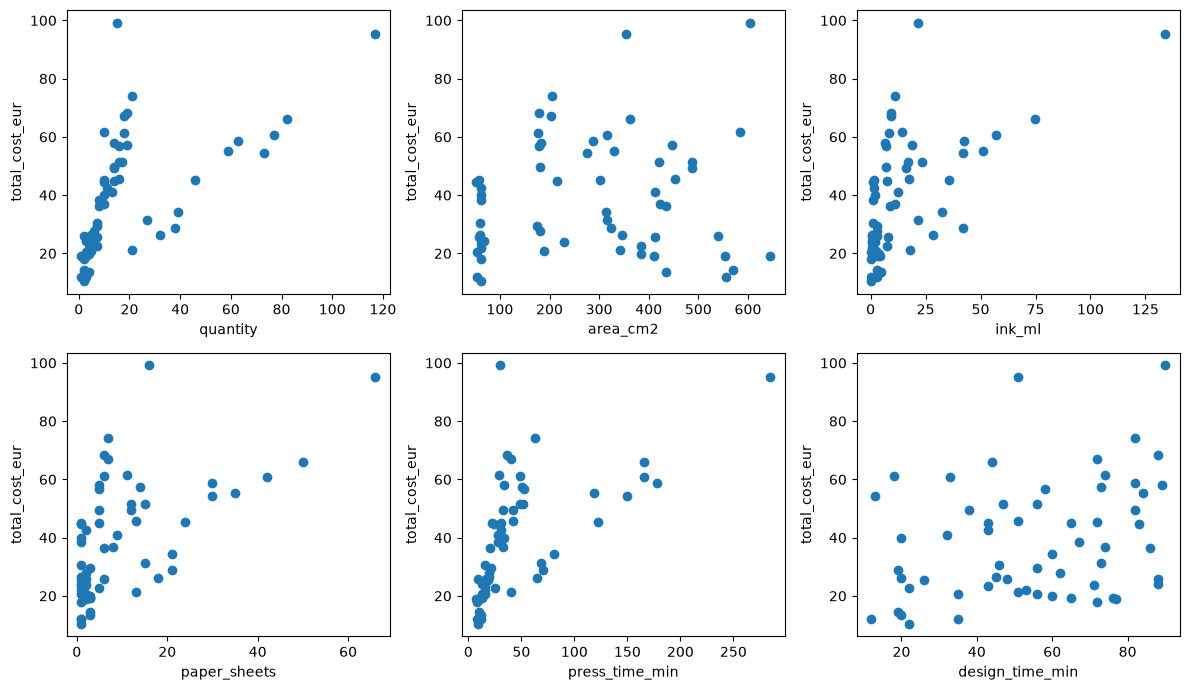

In [21]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, col in zip(axes.flat, cols[:-1][:6]):
    ax.scatter(df_clean[col], df_clean["total_cost_eur"])
    ax.set_xlabel(col)
    ax.set_ylabel("total_cost_eur")
plt.tight_layout()
plt.show()

In [22]:
cols = ["quantity", "area_cm2", "ink_ml", "paper_sheets",
        "press_time_min", "design_time_min", "waste_pct", "total_cost_eur"]
corr = df_clean[cols].corr().round(2)
corr

,quantity,area_cm2,ink_ml,paper_sheets,press_time_min,design_time_min,waste_pct,total_cost_eur
quantity,1.00,0.11,0.95,0.97,0.99,-0.06,-0.04,0.59
area_cm2,0.11,1.00,0.24,0.27,0.10,0.16,-0.14,0.12
ink_ml,0.95,0.24,1.00,0.98,0.95,-0.04,-0.06,0.57
paper_sheets,0.97,0.27,0.98,1.00,0.95,-0.02,-0.06,0.59
press_time_min,0.99,0.10,0.95,0.95,1.00,-0.03,-0.06,0.61
design_time_min,-0.06,0.16,-0.04,-0.02,-0.03,1.00,-0.10,0.32
waste_pct,-0.04,-0.14,-0.06,-0.06,-0.06,-0.10,1.00,-0.16
total_cost_eur,0.59,0.12,0.57,0.59,0.61,0.32,-0.16,1.00


The correlation matrix shows that `quantity`, `ink_ml`, `paper_sheets` and `press_time_min` are almost perfectly correlated with each other (0.95-0.99). This is expected: a bigger order needs more ink, more paper and more time in the press. Such strongly related predictors can make the coefficients of ordinary least squares unstable, which is why we also try Ridge regression later.

The correlation of each of these variables with the total cost is only about 0.6, because the orders are made of different products with different prices of blanks. Design time has a weaker relationship with cost (0.35), the printed area has almost none (0.12), and the waste percentage is very weakly and negatively correlated (-0.17), which is most likely just random variation in a small sample.

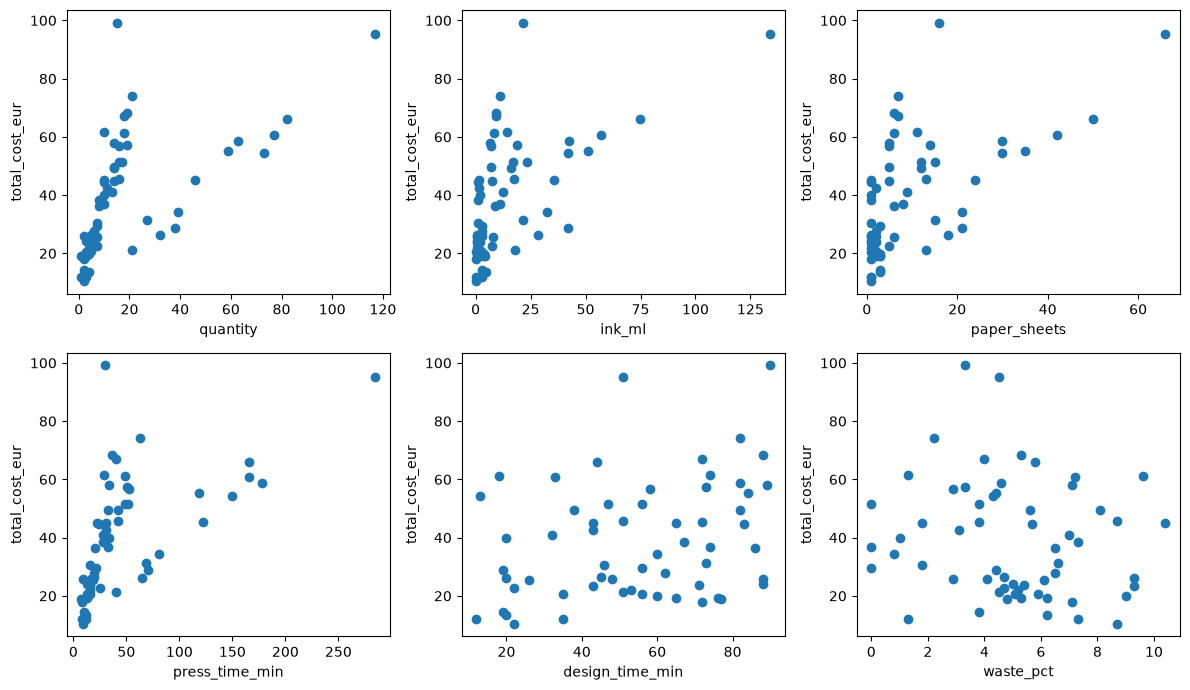

In [23]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, col in zip(axes.flat, ["quantity", "ink_ml", "paper_sheets",
                               "press_time_min", "design_time_min", "waste_pct"]):
    ax.scatter(df_clean[col], df_clean["total_cost_eur"])
    ax.set_xlabel(col)
    ax.set_ylabel("total_cost_eur")
plt.tight_layout()
plt.show()

## 6. Modeling

### 6.1 Simple linear regression

We start with the simplest model: the cost depends only on the quantity,

$$y = \beta_0 + \beta_1 x + \varepsilon.$$

For one predictor, the least squares solution has a simple form:

$$\hat\beta_1 = \frac{\sum_i (x_i-\bar x)(y_i-\bar y)}{\sum_i (x_i-\bar x)^2}, \qquad \hat\beta_0 = \bar y - \hat\beta_1 \bar x.$$

The slope $\hat\beta_1$ tells how many euros the cost grows with one more item in the order.

In [24]:
x = df_clean["quantity"].to_numpy()
y = df_clean["total_cost_eur"].to_numpy()

b1 = ((x - x.mean()) * (y - y.mean())).sum() / ((x - x.mean()) ** 2).sum()
b0 = y.mean() - b1 * x.mean()
y_hat = b0 + b1 * x
r2 = 1 - ((y - y_hat) ** 2).sum() / ((y - y.mean()) ** 2).sum()

print(f"Intercept b0 = {b0:.2f} EUR")
print(f"Slope b1 = {b1:.2f} EUR per item")
print(f"R^2 = {r2:.2f}")

Intercept b0 = 29.55 EUR
Slope b1 = 0.51 EUR per item
R^2 = 0.35


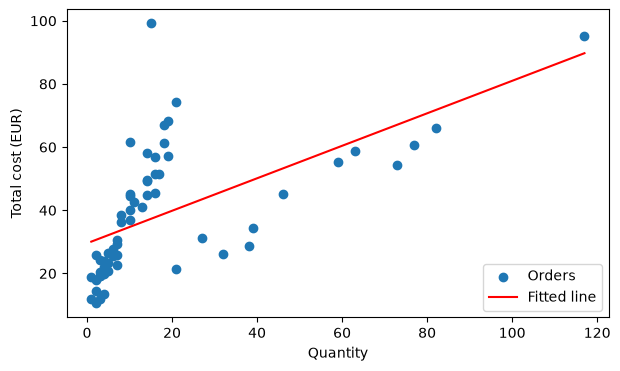

In [25]:
plt.figure(figsize=(7, 4))
plt.scatter(x, y, label="Orders")
xs = np.linspace(x.min(), x.max(), 100)
plt.plot(xs, b0 + b1 * xs, color="red", label="Fitted line")
plt.xlabel("Quantity")
plt.ylabel("Total cost (EUR)")
plt.legend()
plt.show()

The fitted line is $\hat y = 29.55 + 0.51\,x$. The intercept means a "base" cost of about 29.55 EUR for an order, and each additional item adds about 0.51 EUR on average. The coefficient of determination is $R^2 = 0.35$, so the quantity alone explains only 35% of the variation in the cost. This agrees with the correlation $r = 0.59$, because for a simple regression $R^2 = r^2$.

The plot shows why the fit is weak: the line goes between the two groups of orders (expensive items in small amounts and cheap items in large amounts) and describes neither of them well. This motivates a model with more predictors.

### 6.2 Linear regression with matrices

Now we compute the coefficients directly from the formula derived in Section 3,

$$\hat\beta = (X^T X)^{-1} X^T y,$$

using only matrix operations of `numpy`: transposition `.T`, matrix product `@` and inverse `np.linalg.inv`. First we check that for one predictor we get the same numbers as before.

In [26]:
X1 = np.column_stack([np.ones(len(x)), x])   # колона от единици и quantity
beta1 = np.linalg.inv(X1.T @ X1) @ X1.T @ y
print(beta1)

[29.55317851  0.51436523]


The matrix formula gives the same intercept and slope as the formulas for simple regression, so the two approaches agree.

In [27]:
features = [
    "product_type",
    "quantity",
    "ink_ml",
    "paper_sheets",
    "press_time_min",
    "design_time_min",
    "waste_pct"
]

X_df = df_clean[features].copy()

X_df = pd.get_dummies(
    X_df,
    columns=["product_type"],
    drop_first=True,
    dtype=float
)

X = np.column_stack([
    np.ones(len(X_df)),
    X_df.to_numpy()
])

y = df_clean["total_cost_eur"].to_numpy()

beta = np.linalg.inv(X.T @ X) @ X.T @ y

feature_names = ["intercept"] + list(X_df.columns)

for name, b in zip(feature_names, beta):
    print(f"{name:25s} {b:8.3f}")

intercept                  -23.062
quantity                     0.961
ink_ml                      -0.529
paper_sheets                 1.297
press_time_min              -0.045
design_time_min              0.232
waste_pct                   -0.513
product_type_mousepad       34.584
product_type_mug            46.759
product_type_phone_case     36.893
product_type_t-shirt        41.261


### Interpretation of the OLS coefficients

The estimated coefficients show how the explanatory variables are associated with the predicted production cost while the other variables are held constant.

The model includes `product_type` using one-hot encoding. The omitted product category acts as the reference category, while the coefficients of the remaining product types represent their estimated difference relative to this reference.

Several numerical variables have negative coefficients, such as `ink_ml`, `press_time_min`, and `waste_pct`. These negative signs do not mean that increasing ink, pressing time, or waste actually reduces production cost. Instead, they are a consequence of the strong multicollinearity between several explanatory variables.

For example, `quantity`, `ink_ml`, `paper_sheets`, and `press_time_min` are strongly correlated because larger orders generally require more materials and production time. As a result, ordinary least squares regression can produce unstable coefficients and unexpected signs when the variables contain overlapping information.

This is an important limitation of the OLS model and provides a motivation for comparing it with Ridge Regression later in the project.

Mathematically, the OLS model estimates the coefficient vector by minimizing the sum of squared residuals:

$$
\hat{\beta}
=
\arg\min_{\beta}
\sum_{i=1}^{n}
(y_i-\hat{y}_i)^2
$$

or, in matrix form:

$$
\hat{\beta}
=
(X^TX)^{-1}X^Ty
$$

The Ridge model will later add a regularization term to reduce the instability of the estimated coefficients.


In [43]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", len(X_train))
print("Test samples:", len(X_test))

Training samples: 47
Test samples: 12


In [44]:
from sklearn.linear_model import LinearRegression

ols_model = LinearRegression()

ols_model.fit(X_train, y_train)

y_pred = ols_model.predict(X_test)

print("OLS model trained successfully.")

OLS model trained successfully.


In [45]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"R²:   {r2:.3f}")
print(f"MAE:  {mae:.3f} EUR")
print(f"RMSE: {rmse:.3f} EUR")

R²:   0.558
MAE:  11.240 EUR
RMSE: 12.102 EUR


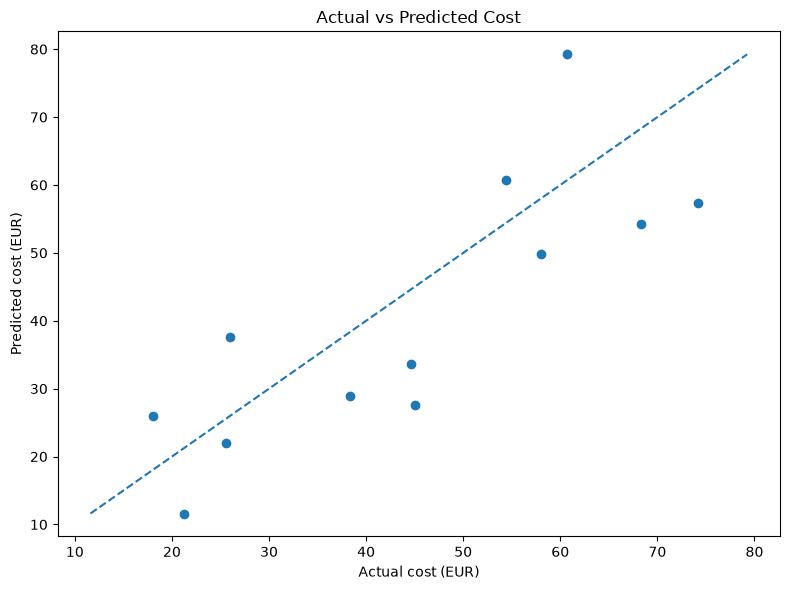

In [46]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred)

min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual cost (EUR)")
plt.ylabel("Predicted cost (EUR)")
plt.title("Actual vs Predicted Cost")

plt.tight_layout()
plt.show()

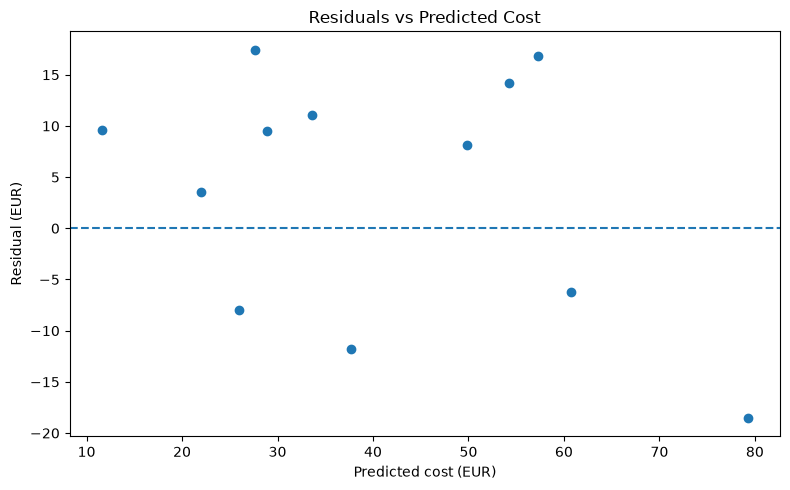

In [47]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 5))

plt.scatter(y_pred, residuals)

plt.axhline(0, linestyle="--")

plt.xlabel("Predicted cost (EUR)")
plt.ylabel("Residual (EUR)")
plt.title("Residuals vs Predicted Cost")

plt.tight_layout()
plt.show()

In [48]:
print("Mean residual:", round(residuals.mean(), 3))
print("Median residual:", round(np.median(residuals), 3))

Mean residual: 3.826
Median residual: 8.85


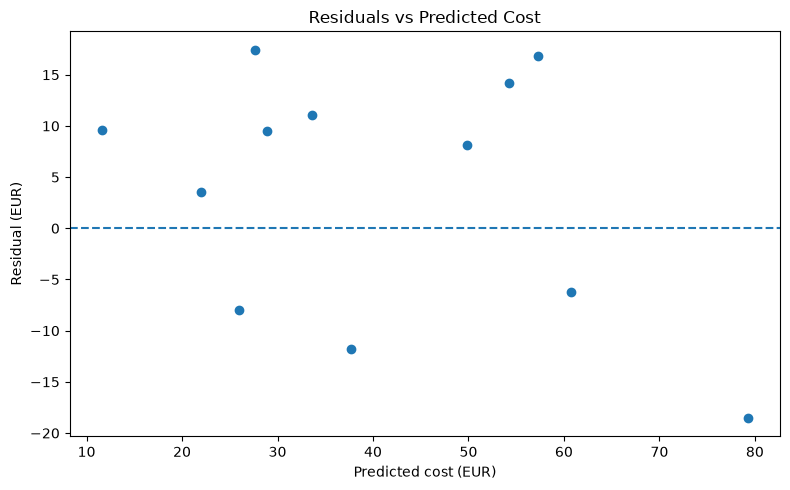

In [49]:
plt.figure(figsize=(8, 5))

plt.scatter(y_pred, residuals)

plt.axhline(0, linestyle="--")

plt.xlabel("Predicted cost (EUR)")
plt.ylabel("Residual (EUR)")
plt.title("Residuals vs Predicted Cost")

plt.tight_layout()
plt.show()

In [50]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    ols_model,
    X,
    y,
    cv=5,
    scoring="r2"
)

print("Cross-validation R² scores:")
print(np.round(cv_scores, 3))

print("Mean CV R²:", round(cv_scores.mean(), 3))

Cross-validation R² scores:
[ 0.486  0.284 -0.339  0.469 -0.034]
Mean CV R²: 0.173


In [51]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

ridge_model = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=1.0))
])

ridge_model.fit(X_train, y_train)

ridge_pred = ridge_model.predict(X_test)

print("Ridge model trained successfully.")

Ridge model trained successfully.


In [52]:
ridge_r2 = r2_score(y_test, ridge_pred)
ridge_mae = mean_absolute_error(y_test, ridge_pred)
ridge_rmse = np.sqrt(mean_squared_error(y_test, ridge_pred))

print(f"Ridge R²:   {ridge_r2:.3f}")
print(f"Ridge MAE:  {ridge_mae:.3f} EUR")
print(f"Ridge RMSE: {ridge_rmse:.3f} EUR")

Ridge R²:   0.616
Ridge MAE:  9.920 EUR
Ridge RMSE: 11.279 EUR


In [53]:
ridge_cv_scores = cross_val_score(
    ridge_model,
    X,
    y,
    cv=5,
    scoring="r2"
)

print("Ridge cross-validation R² scores:")
print(np.round(ridge_cv_scores, 3))

print("Mean Ridge CV R²:", round(ridge_cv_scores.mean(), 3))

Ridge cross-validation R² scores:
[0.501 0.234 0.64  0.42  0.125]
Mean Ridge CV R²: 0.384


In [54]:
comparison = pd.DataFrame({
    "Model": ["OLS", "Ridge"],
    "R²": [r2, ridge_r2],
    "MAE (EUR)": [mae, ridge_mae],
    "RMSE (EUR)": [rmse, ridge_rmse],
    "Mean CV R²": [cv_scores.mean(), ridge_cv_scores.mean()]
})

comparison

,Model,R²,MAE (EUR),RMSE (EUR),Mean CV R²
0,OLS,0.557819,11.239569,12.101578,0.173134
1,Ridge,0.615900,9.920405,11.278831,0.383769


### OLS vs Ridge Regression

The results show that Ridge Regression performs better than Ordinary Least Squares (OLS) on the synthetic dataset.

The OLS model achieved a test \(R^2\) of 0.558, while the Ridge model achieved a higher \(R^2\) of 0.616. At the same time, Ridge reduced the Mean Absolute Error (MAE) from 11.240 EUR to 9.920 EUR and the Root Mean Squared Error (RMSE) from 12.102 EUR to 11.279 EUR.

The cross-validation results also indicate better stability for Ridge Regression. The mean cross-validation \(R^2\) increased from 0.173 for OLS to 0.384 for Ridge.

This improvement is consistent with the strong multicollinearity present in the dataset. Several predictors, such as quantity, ink consumption, paper usage, and press time, are strongly correlated. OLS can produce unstable coefficient estimates in the presence of multicollinearity.

Ridge Regression addresses this problem by adding an \(L_2\) regularization term to the ordinary least squares objective function:

$$
\hat{\beta}_{Ridge}
=
\arg\min_{\beta}
\left[
\sum_{i=1}^{n}(y_i-\hat{y}_i)^2
+
\alpha\sum_{j=1}^{p}\beta_j^2
\right]
$$

where \(\alpha\) controls the strength of regularization.

The regularization term penalizes large coefficients and reduces their magnitude. This can make the model more stable when predictors are strongly correlated.

For this dataset, Ridge Regression provides better predictive performance and better cross-validation stability than OLS. However, the dataset contains only 59 observations, so these results should be interpreted as evidence for this particular dataset rather than as a general conclusion that Ridge is always superior to OLS.


## 7. Model Diagnostics

Model diagnostics are used to evaluate whether the regression model is appropriate for the data and whether its predictions and errors show systematic patterns.

In this section, the residuals of the OLS model will be examined using graphical and statistical methods. Residuals represent the difference between the observed cost and the cost predicted by the model:

$$
e_i = y_i - \hat{y}_i
$$

where \(e_i\) is the residual, \(y_i\) is the observed cost, and \(\hat{y}_i\) is the predicted cost.

The main diagnostic checks will focus on the distribution of residuals, their relationship with predicted values, and the presence of systematic patterns. These checks help determine whether the model errors are reasonably well behaved and whether there are indications of model misspecification.

Because the dataset is relatively small and synthetic, the diagnostic results will be interpreted as evidence about the behavior of the model on this particular dataset rather than as universal conclusions.


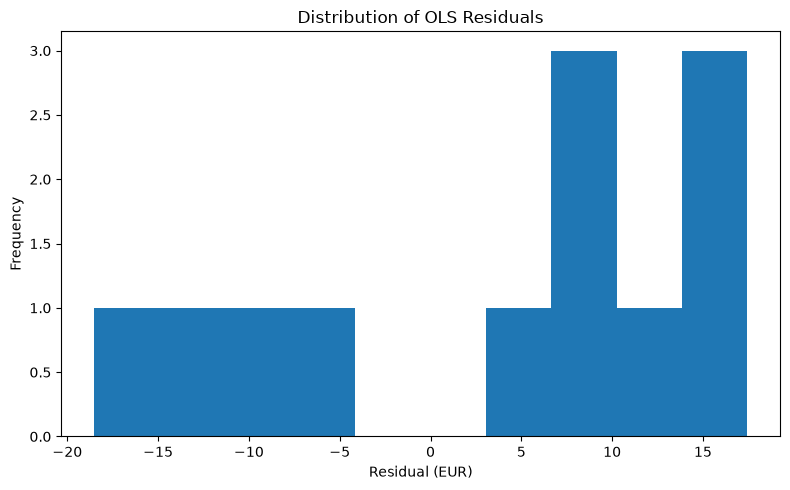

In [56]:
plt.figure(figsize=(8, 5))

plt.hist(residuals, bins=10)

plt.xlabel("Residual (EUR)")
plt.ylabel("Frequency")
plt.title("Distribution of OLS Residuals")

plt.tight_layout()
plt.show()

In [57]:
print("Mean residual:", round(residuals.mean(), 3))
print("Median residual:", round(np.median(residuals), 3))
print("Standard deviation:", round(residuals.std(), 3))
print("Minimum residual:", round(residuals.min(), 3))
print("Maximum residual:", round(residuals.max(), 3))

Mean residual: 3.826
Median residual: 8.85
Standard deviation: 11.481
Minimum residual: -18.537
Maximum residual: 17.442


### Interpretation of the Residual Distribution

The residuals range from approximately \(-18.54\) EUR to \(17.44\) EUR, with a standard deviation of \(11.48\) EUR. This indicates that the prediction errors have a noticeable spread around the expected value.

The mean residual is \(3.83\) EUR, while the median residual is \(8.85\) EUR. Both values are positive, indicating a tendency of the OLS model to underestimate the actual cost for a substantial part of the test observations.

The difference between the mean and median residual also suggests that the residual distribution is not perfectly symmetric. Therefore, the residuals should not be considered perfectly normally distributed based on these descriptive statistics alone.

Since the dataset contains only 59 observations, small deviations from normality are not unexpected. The residual distribution will therefore be considered together with the other diagnostic checks rather than used as a standalone criterion for rejecting the model.


### Residuals vs Predicted Values

A residuals-versus-predicted plot is used to examine whether the model errors show systematic patterns.

The residuals are calculated as:

$$
e_i = y_i - \hat{y}_i
$$

where \(y_i\) is the observed cost and \(\hat{y}_i\) is the predicted cost.

In a well-behaved linear regression model, the residuals should be distributed approximately randomly around the horizontal zero line. There should be no clear curve, trend, or funnel-shaped pattern.

A systematic pattern may indicate that the model does not fully capture the relationship between the predictors and the target variable. Increasing spread of residuals as the predicted value increases may also indicate heteroscedasticity.

The following plot is used to visually assess these patterns.


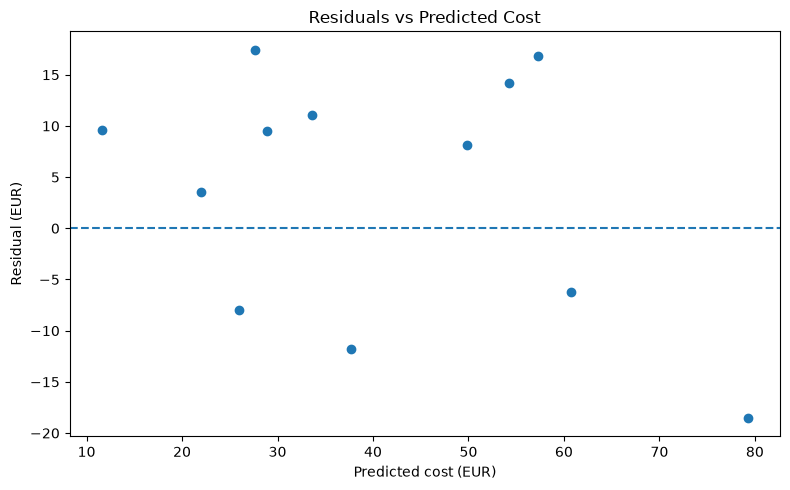

In [60]:
plt.figure(figsize=(8, 5))

plt.scatter(y_pred, residuals)

plt.axhline(0, linestyle="--")

plt.xlabel("Predicted cost (EUR)")
plt.ylabel("Residual (EUR)")
plt.title("Residuals vs Predicted Cost")

plt.tight_layout()
plt.show()

In [61]:
correlation = np.corrcoef(y_pred, residuals)[0, 1]

print("Correlation between predicted values and residuals:",
      round(correlation, 3))

Correlation between predicted values and residuals: -0.352


### Interpretation of Residuals vs Predicted Values

The correlation between the predicted values and the residuals is **-0.352**. This indicates a moderate negative relationship between predicted cost and prediction errors.

The result suggests that the residuals are not completely independent of the predicted values and that the OLS model may contain some systematic prediction error. However, the correlation is not strong enough to indicate a severe problem by itself.

Overall, the residual analysis suggests that the model provides useful predictions, but its errors are not perfectly random. This is reasonable given the small size and synthetic nature of the dataset.


In [62]:
from scipy.stats import shapiro

stat, p_value = shapiro(residuals)

print("Shapiro-Wilk statistic:", round(stat, 3))
print("p-value:", round(p_value, 3))

Shapiro-Wilk statistic: 0.9
p-value: 0.161


### Interpretation of the Shapiro-Wilk Test

The Shapiro-Wilk test was used to assess whether the residuals are approximately normally distributed.

The test produced a statistic of **0.900** and a p-value of **0.161**. Since the p-value is greater than 0.05, there is insufficient evidence to reject the assumption of normality.

Therefore, the residuals can be considered approximately normally distributed for this dataset. However, the result should be interpreted cautiously because the test set contains only 12 observations.

Overall, the diagnostic checks indicate that the OLS model has some systematic prediction error, but there is no strong statistical evidence of a serious violation of the normality assumption.


## 8. Comparison of Methods
*TODO: OLS vs Ridge. Metrics: RMSE, MAE, $R^2$.*

## 9. Price Calculator
*TODO: A function that takes order parameters and returns a recommended price with a profit margin.*

In [ ]:
def recommend_price(order, model, margin=0.3):
    """Return the recommended price for an order."""
    raise NotImplementedError

## 10. Conclusions & Next Steps
*TODO: Findings, limitations, possible improvements.*

## 11. References
The notebook structure and the simulated data generator were created with the help of an AI 
assistant (Claude). The analysis and conclusions are my own.